# 1. Imports

In [1]:
# ==================== IMPORTS ====================
import numpy as np
import pandas as pd
from collections import Counter
import matplotlib.pyplot as plt

# ==================== GLOBAL CONFIGURATION ====================
RANDOM_STATE = 42

# 2. Load Data

In [2]:
# Load data
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

# Normalize column names
train.columns = train.columns.str.lower()
test.columns = test.columns.str.lower()

# Extract and remove Test ID
test_id = test.pop("id") if "id" in test.columns else test.index.copy()

# Remove Train ID
if "id" in train.columns:
    train = train.drop(columns=["id"])

# 3. Data Validation Report

                                                          DATA INFORMATION REPORT                                                           

[1] DATA OVERVIEW
--------------------------------------------------------------------------------------------------------------------------------------------
Training dataset shape        : (18524, 8)
Test dataset shape            : (6175, 7)
Training features             : 8
Test features                 : 7

[2] COLUMN INFORMATION
--------------------------------------------------------------------------------------------------------------------------------------------
Training columns              : ['time_spent_alone', 'stage_fear', 'social_event_attendance', 'going_outside', 'drained_after_socializing', 'friends_circle_size', 'post_frequency', 'personality']
Test columns                  : ['time_spent_alone', 'stage_fear', 'social_event_attendance', 'going_outside', 'drained_after_socializing', 'friends_circle_size', 'post_frequency']

[3]

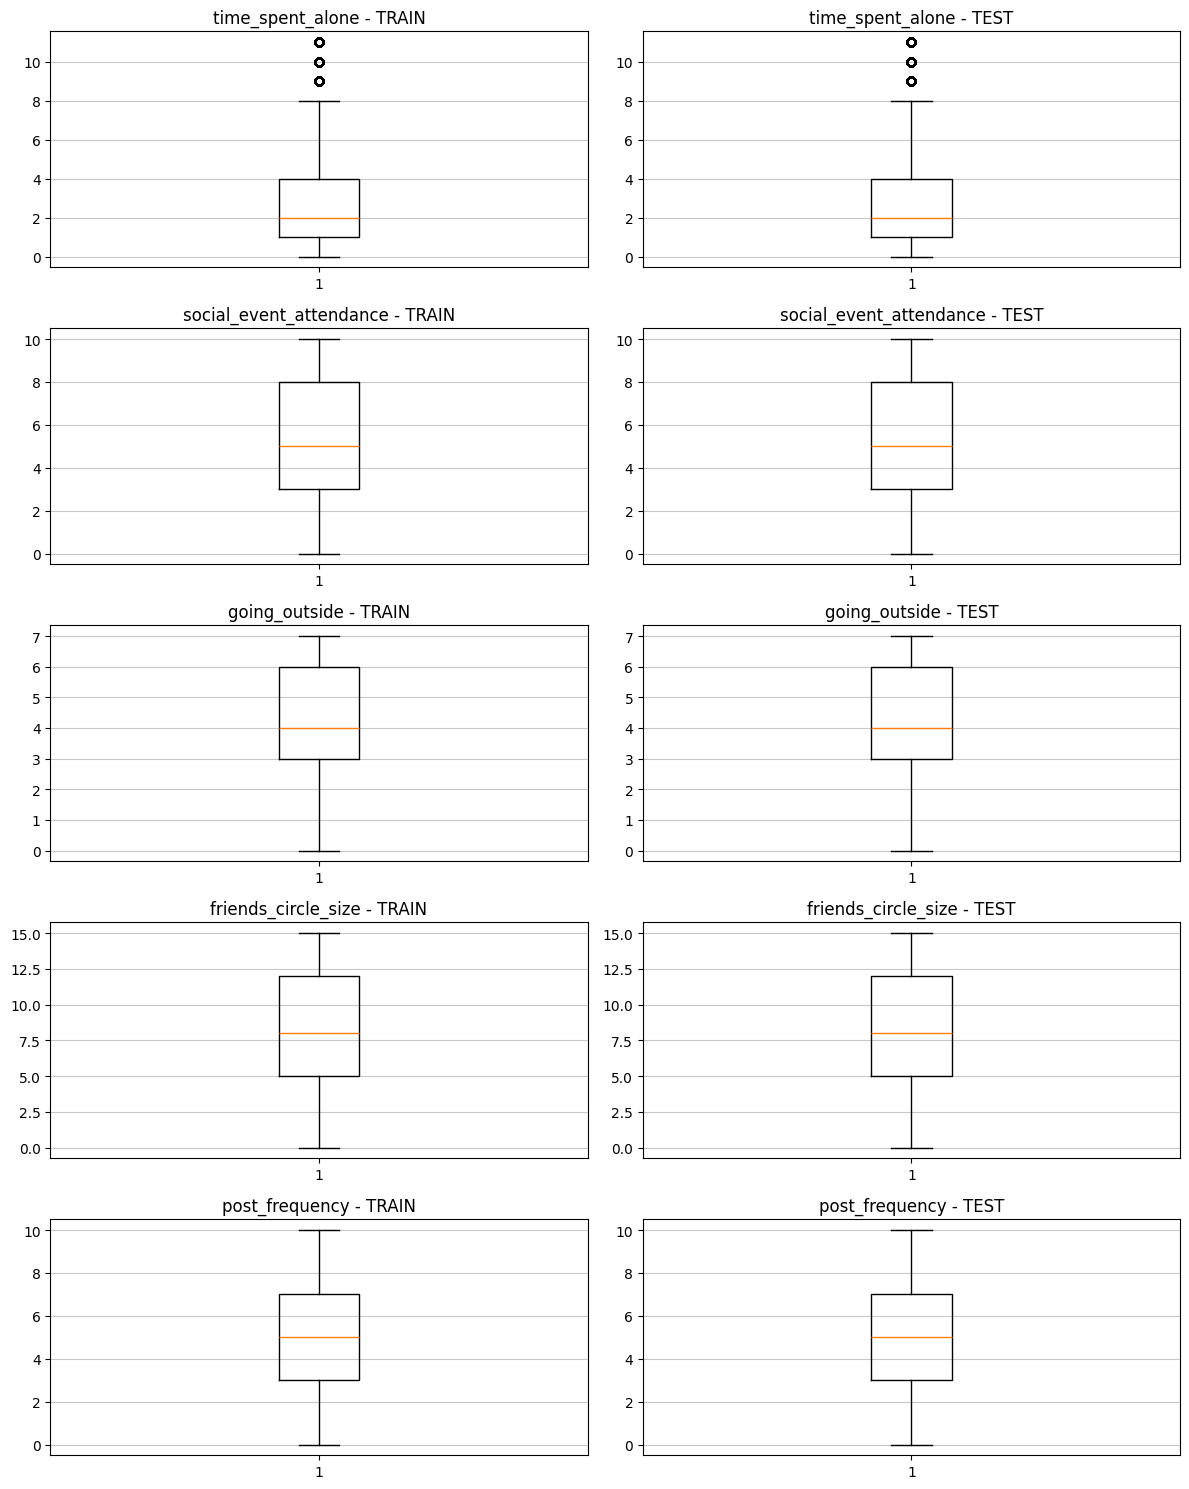


[8] OBJECT VALUES
--------------------------------------------------------------------------------------------------------------------------------------------
STATUS: PASS - no object anomalies detected 🟢


In [3]:
# ============================================================
# DATA VALIDATION REPORT
# Pipeline checks: column alignment, missing values,
# duplicates, numeric outliers + boxplots,
# inconsistent categorical values
# ============================================================

# ---- Report configuration ----
WIDTH = 140            # line width for report output
target = "personality" # Target column (expected: Train-only)

# ============================================================
# [1] DATA OVERVIEW
# ============================================================
print("=" * WIDTH)
print("DATA INFORMATION REPORT".center(WIDTH))
print("=" * WIDTH)

print("\n" + "[1] DATA OVERVIEW")
print("-" * WIDTH)

# Shape tells us sample size and feature count at a glance
print(f"{'Training dataset shape':<30}: {train.shape}")
print(f"{'Test dataset shape':<30}: {test.shape}")

# Explicit feature counts - catches duplicate column names
# that would inflate train.shape[1] invisibly
print(f"{'Training features':<30}: {len(train.columns)}")
print(f"{'Test features':<30}: {len(test.columns)}")

# ============================================================
# [2] COLUMNS INFORMATION
# ============================================================
print("\n" + "[2] COLUMN INFORMATION")
print("-" * WIDTH)

print(f"{'Training columns':<30}: {train.columns.tolist()[:15] or '{none}'}")
print(f"{'Test columns':<30}: {test.columns.tolist()[:15] or '{none}'}")

# ============================================================
# [3] NUMERIC COLUMNS DESCRIPTION
# describe() prints count/mean/std/min/quartiles/max per column.
# This is the first-pass health scan: it surfaces missing values
# (count), outliers (min/max vs the 25-75% crowd), and skew
# (mean far from the 50% median) before any dedicated check runs.
# ============================================================
print("\n" + "[3] NUMERIC COLUMNS DESCRIPTION")
print("-" * WIDTH)

# Numeric-only views - describe() on the full frame would mix in
# object columns and produce meaningless stats for them
train_num = train.select_dtypes(include=np.number)
test_num = test.select_dtypes(include=np.number)

# .empty is True when a frame has no columns (all-text dataset);
# describe() on an empty frame raises, so guard both sides
train_description = train_num.describe().T if not train_num.empty else '{none}'
test_description = test_num.describe().T if not test_num.empty else '{none}'

print(f"Train Numeric Description:\n{train_description}")
print(f"\nTest Numeric Description:\n{test_description}")

# ============================================================
# [4] COLUMN VALIDATION
# Expectation: identical features in both sets,
# ============================================================
print("\n" + "[4] COLUMN VALIDATION")
print("-" * WIDTH)

# Counter preserves duplicate columns that set() would silently drop,
# so mismatches in column *counts* are caught, not just column names.
train_only = Counter(train.columns) - Counter(test.columns)
test_only = Counter(test.columns) - Counter(train.columns)

if not train_only and not test_only:
    print("STATUS: PASS - no exclusive features detected 🟢\n")
elif train_only and train_only == Counter({target: 1}) and not test_only:
    # Target is expected to exist only in train - 
    # no unexpected exclusive features.
    print(f"STATUS: INFO - target column exists only in train: {target} 🔵")
    print(f"  {'Target in Train':<30}: {dict(train_only)}")
elif train_only and not test_only:
    # Model trains on these columns but they vanish at inference time -
    # the prediction pipeline breaks or silently imputes garbage.
    print("STATUS: WARNING - train-exclusive features detected 🟡")
    print(f"  {'Features exclusive to Train':<30}: {dict(train_only)}")
elif not train_only and test_only:
    # The model never learns weights for these - they are dead weight
    # in test, or worse, a sign of a leaky/incorrect split.
    print("STATUS: WARNING - test-exclusive features detected 🟡")
    print(f"  {'Features exclusive to Test':<30}: {dict(test_only)}")
else:
    # Both sides have their own columns: the split is misaligned.
    print("STATUS: ERROR - exclusives on both sides - split is broken 🔴")
    print(f"  {'Features exclusive to Train':<30}: {dict(train_only)}")
    print(f"  {'Features exclusive to Test':<30}: {dict(test_only)}")
    
# ============================================================
# [5] DUPLICATES
# duplicated() marks copies AFTER the first occurrence: the first is the
# "original", everything flagged here is an extra copy to investigate.
# ============================================================
print("\n" + "[5] DUPLICATES")
print("-" * WIDTH)

train_dup_mask = train.columns.duplicated()
test_dup_mask = test.columns.duplicated()

# Row duplicates overweight those samples during training - count only,
# materializing the rows here would waste memory for a number.
train_dup_cnt = train.duplicated().sum()
test_dup_cnt = test.duplicated().sum()

if not train_dup_mask.any() and not test_dup_mask.any():
    print("STATUS: PASS - no duplicate columns detected 🟢")
else:
    print(f"{'Train duplicate columns:':<30}: {train.columns[train_dup_mask].tolist()}")
    print(f"{'Test duplicate columns:':<30}: {test.columns[test_dup_mask].tolist()}")
    
# Add space
print()

if train_dup_cnt == 0 and test_dup_cnt == 0:
    print("STATUS: PASS - no duplicate rows detected 🟢")
else:
    print(f"{'Train duplicate rows:':<30}: {train_dup_cnt}")
    print(f"{'Test duplicate rows:':<30}: {test_dup_cnt}")

# ============================================================
# [6] MISSING VALUES
# Per-column missing counts and percentage for both datasets,
# sorted so the most damaged column is always on top.
# ============================================================
print("\n" + "[6] MISSING VALUES")
print("-" * WIDTH)

# Count and percentage per column, for both datasets
train_missing_cnt = train.isnull().sum()
train_missing_pct = train.isnull().mean() * 100
test_missing_cnt = test.isnull().sum()
test_missing_pct = test.isnull().mean() * 100

missing_report = pd.DataFrame({
    'train_cnt': train_missing_cnt,
    'train_pct': train_missing_pct.round(2),
    'test_cnt':  test_missing_cnt,
    'test_pct':  test_missing_pct.round(2)
})

# Sort by the worst side of each column: sorting by train alone would
# bury a column that's clean in train but heavily missing in test.
missing_report['worst_pct'] = missing_report[['train_pct', 'test_pct']].max(axis=1)
missing_report = missing_report.sort_values('worst_pct', ascending=False)
missing_report = missing_report.drop(columns='worst_pct')

if train_missing_cnt.sum() == 0 and test_missing_cnt.sum() == 0:
    print("STATUS: PASS - no missing values detected 🟢")
else:
    print(missing_report.to_string())
    
# ============================================================
# [7] NUMERIC OUTLIERS (IQR fence)
# Fence computed on TRAIN only, applied to both datasets.
# ============================================================
print("\n" + "[7] NUMERIC OUTLIERS")
print("-" * WIDTH)

train_num_cols = train_num.columns
test_num_cols = test_num.columns

diff_cols = train_num_cols.symmetric_difference(test_num_cols)
if len(diff_cols) > 0:
    print("STATUS: WARNING - numeric column sets differ between train and test 🟡")
    print(f"  non-matching columns: {list(diff_cols)}\n")

# Only columns existing on BOTH sides can be compared - shrink to the
# common set, the mismatch was reported above (see section [3]).
num_cols = train_num_cols.intersection(test_num_cols, sort=False)

if len(num_cols) == 0:
    print("STATUS: PASS - no common numeric columns - section skipped 🟢")
else:
    # Compute the fence for all numeric columns in four vectorized lines.
    # q1/q3/iqr are Series - one value per column, no loops.
    q1 = train[num_cols].quantile(0.25)
    q3 = train[num_cols].quantile(0.75)
    iqr = q3 - q1
    
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    # Boolean mask: True where a value sits outside the fence.
    # One train-learned fence, held against both datasets - same ruler,
    # fair comparison.
    # NaN cells become False automatically - they belong to section [5].
    outside_fence_train = (train[num_cols] < lower_bound) | (train[num_cols] > upper_bound)
    outlier_cnt_train = outside_fence_train.sum()
    
    outside_fence_test = (test[num_cols] < lower_bound) | (test[num_cols] > upper_bound)
    outlier_cnt_test = outside_fence_test.sum()
    
    # Report: violation count, fence, and actual min/max for inspection.
    # min/max let you judge "impossible" vs "rare but real" without
    # extracting rows - the report answers, the human decides.
    outlier_report = pd.DataFrame({
        'train_cnt':  outlier_cnt_train,
        'test_cnt':   outlier_cnt_test,
        'train_min':  train[num_cols].min(),
        'train_max':  train[num_cols].max(),
        'test_min':   test[num_cols].min(),
        'test_max':   test[num_cols].max(),
        'fence_low':  lower_bound.round(2),
        'fence_high': upper_bound.round(2),
    })
    
    # A column dirty on EITHER side makes the report; worst offender on top
    outlier_report = outlier_report[(outlier_report['train_cnt'] > 0) |
                                    (outlier_report['test_cnt'] > 0)]
    outlier_report['worst_cnt'] = outlier_report[['train_cnt', 'test_cnt']].max(axis=1)
    outlier_report = outlier_report.sort_values('worst_cnt', ascending=False)
    outlier_report = outlier_report.drop(columns='worst_cnt')

    if outlier_report.empty:
        print("STATUS: PASS - no numeric outliers detected 🟢")
    else:
        print(outlier_report.to_string())

        print("\n" + "Boxplots (train vs test)".center(WIDTH))
        print("-" * WIDTH)
    
        # Duplicated names break train[col] (returns a DataFrame, not a Series).
        # Report which names got collapsed; the full diagnosis lives in [3].
        dup_in_plot = num_cols[num_cols.duplicated()].tolist()
        if dup_in_plot:
            print(f"STATUS: WARNING - duplicated names plotted once (first copy): {dup_in_plot} 🟡")
        num_cols = num_cols[~num_cols.duplicated()]
        
        fig, axes = plt.subplots(len(num_cols), 2,
                                 figsize=(12, 3 * len(num_cols)),
                                 squeeze=False)
        
        for i, col in enumerate(num_cols):
            # Share the y-axis across the row BEFORE plotting:
            # same scale on both sides, or the comparison lies.
            axes[i, 0].sharey(axes[i, 1])
        
            axes[i, 0].boxplot(train[col].dropna())
            axes[i, 0].set_title(f"{col} - TRAIN")
            axes[i, 0].grid(axis='y', alpha=0.7)
        
            axes[i, 1].boxplot(test[col].dropna())
            axes[i, 1].set_title(f"{col} - TEST")
            axes[i, 1].grid(axis='y', alpha=0.7)
        
        plt.tight_layout()
        plt.show()

# ============================================================
# [8] OBJECT VALUES
# Four checks per text column: case/whitespace variants, rare values
# (typo strangers), numeric-in-disguise, test-only categories.
# Flags only - fixing happens in the treatment cell after inspection.
# Detection runs on RAW data; normalized views are used only where a
# comparison needs them, so evidence is never destroyed before it's seen.
# ============================================================
print("\n" + "[8] OBJECT VALUES")
print("-" * WIDTH)

RARE_PCT = 1       # categories rarer than this % of rows are typo suspects
NUMERIC_PCT = 90   # object column with more % convertible = numeric-in-disguise

train_cat_cols = train.select_dtypes(include='object').columns
test_cat_cols  = test.select_dtypes(include='object').columns

# Same guard philosophy as [6]: warn on mismatch, work on the common set
diff_cat = train_cat_cols.symmetric_difference(test_cat_cols)
if len(diff_cat) > 0 and diff_cat != [target]:
    print("STATUS: WARNING - object column sets differ between train and test 🟡")
    print(f"  non-matching columns: {list(diff_cat)}\n")

cat_cols = train_cat_cols.intersection(test_cat_cols, sort=False)

if len(cat_cols) == 0:
    print("STATUS: PASS - no common object columns - section skipped 🟢")
else:
    # Check 3 first (numeric-in-disguise) so disguised numbers don't
    # pollute the categorical checks below with hundreds of fake "categories"
    numeric_obj_cols = []
    for col in cat_cols:
        valid_cnt   = train[col].notna().sum()
        numeric_cnt = pd.to_numeric(train[col], errors='coerce').notna().sum()
        if valid_cnt > 0 and (numeric_cnt / valid_cnt) * 100 >= NUMERIC_PCT:
            numeric_obj_cols.append(col)

    categorical_obj_cols = cat_cols.drop(numeric_obj_cols)

    if numeric_obj_cols:
        print(f"STATUS: WARNING - numeric-in-disguise (>= {NUMERIC_PCT}% convertible):")
        print(f"  {numeric_obj_cols}\n")

    any_issues = False
    for col in categorical_obj_cols:
        issues = []

        # Check 1: same category in different clothes.
        # train_norm is a VIEW for comparison only - train[col] stays raw.
        train_norm = train[col].dropna().astype(str).str.strip().str.lower()
        if train_norm.nunique() < train[col].nunique():
            variants = sorted(set(train[col].dropna().astype(str)) - set(train_norm.unique()))
            issues.append(f"case/whitespace variants: {variants[:3]}")

        # Check 2: typo strangers - real categories come in crowds,
        # typos come alone. Raw data, so variants stay visible as crumbs.
        vc = train[col].value_counts(normalize=True) * 100
        rare = vc[vc < RARE_PCT]
        if len(rare) > 0:
            issues.append(f"{len(rare)} rare values (<{RARE_PCT}%): "
                          f"{dict(rare.round(2).head(3))}")

        # Check 4: values test has but train never saw. Compared through
        # the view, so 'LONDON' vs 'London' doesn't false-alarm as unseen.
        test_norm = test[col].dropna().astype(str).str.strip().str.lower()
        unseen = set(test_norm.unique()) - set(train_norm.unique())
        if len(unseen) > 0:
            issues.append(f"{len(unseen)} test-only values: {list(unseen)[:3]}")

        if issues:
            any_issues = True
            print(f"[{col}]")
            for i in issues:
                print(f"   - {i}")

    if not any_issues and not numeric_obj_cols:
        print("STATUS: PASS - no object anomalies detected 🟢")
print("=" * WIDTH)

# 4. Data Cleaning

In [4]:
# ============================================================
# DATA CLEANING
# Pipeline handling: missing values
# ============================================================

# ---- Report configuration ----

train.head(5)

,time_spent_alone,stage_fear,social_event_attendance,going_outside,drained_after_socializing,friends_circle_size,post_frequency,personality
0,0.0,No,6.0,4.0,No,15.0,5.0,Extrovert
1,1.0,No,7.0,3.0,No,10.0,8.0,Extrovert
2,6.0,Yes,1.0,0.0,NaN,3.0,0.0,Introvert
3,3.0,No,7.0,3.0,No,11.0,5.0,Extrovert
4,1.0,No,4.0,4.0,No,13.0,NaN,Extrovert


In [5]:
# ============================================================
# [1] Missing Values - Numeric Columns
# Imputation strategy: fill numeric gaps with the column mean.
# A report DataFrame is built for each split to keep an auditable
# record of which columns were modified and which values were used.
# ============================================================
print("=" * WIDTH)
print("Missing Numeric Values".center(WIDTH))
print("=" * WIDTH)

# Accumulators for the imputation reports (list of dicts -> DataFrame later)
train_rep = []
test_rep = []

# Identify numeric columns that contain missing values in each split
train_missing_num = train_num.columns[train_num.isna().any()]
test_missing_num = test_num.columns[test_num.isna().any()]

# --- Train split ---
# Impute missing values with the column mean.
# IMPORTANT: both train and test are filled using TRAIN's means.
# Using the test set's own statistics would leak test-set information
# and shift feature distributions between training and inference.
for col in train_missing_num:
    mean_value = train[col].mean()
    train[col] = train[col].fillna(mean_value)
    train_rep.append({
        'Column': col,
        'mean_value': round(mean_value, 2)
    })

# --- Test split ---
# Same imputation rule, same train-derived means. A separate loop is
# used (rather than one shared loop) so that columns missing in only
# one split are still processed.
for col in test_missing_num:
    mean_value = train[col].mean()
    test[col] = test[col].fillna(mean_value)
    test_rep.append({
        'Column': col,
        'mean_value': round(mean_value, 2)
    })

# Convert the report accumulators into DataFrames for readable output
train_rep = pd.DataFrame(train_rep)
test_rep = pd.DataFrame(test_rep)

# Display the imputation reports
print("Train Handled Features:")
print(train_rep)
print(f"\nTest Handled Features:")
print(test_rep)

                                                           Missing Numeric Values                                                           
Train Handled Features:
                    Column  mean_value
0         time_spent_alone        3.14
1  social_event_attendance        5.27
2            going_outside        4.04
3      friends_circle_size        8.00
4           post_frequency        4.98

Test Handled Features:
                    Column  mean_value
0         time_spent_alone        3.14
1  social_event_attendance        5.27
2            going_outside        4.04
3      friends_circle_size        8.00
4           post_frequency        4.98


In [6]:
# ============================================================
# [2] Missing Values - Object Columns
# Strategy: random sample imputation. Missing values are filled
# by sampling from the observed category distribution, which
# preserves the original class proportions (unlike mode filling,
# which inflates the most frequent category).
# A fixed seed (RANDOM_STATE) makes the random fills reproducible.
# ============================================================
print("=" * WIDTH)
print("Missing Object Values".center(WIDTH))
print("=" * WIDTH)

rng = np.random.default_rng(RANDOM_STATE)

# Accumulators for the imputation reports (list of dicts -> DataFrame later)
train_rep_obj = []
test_rep_obj = []

# Select object (string/categorical) columns in each split
train_obj = train.select_dtypes(include=['object'])
test_obj = test.select_dtypes(include=['object'])

# Identify object columns that contain missing values in each split
train_missing_obj = train_obj.columns[train_obj.isna().any()]
test_missing_obj = test_obj.columns[test_obj.isna().any()]

# --- Train split ---
# Sampled from the train column's own category frequencies
for col in train_missing_obj:
    missing_mask = train[col].isna()
    probabilities = train[col].value_counts(normalize=True)

    # Fill each missing slot with a random draw from the observed categories
    train.loc[missing_mask, col] = rng.choice(
        probabilities.index,
        size=missing_mask.sum(),
        p=probabilities.values
    )
    train_rep_obj.append({
        'Columns': col,
        'probabilities': probabilities.round(2).to_dict()
    })

# --- Test split ---
# Uses TRAIN's category distribution (train[col].value_counts), never test's
# own — same anti-leakage rule as the mean imputation above: statistics
# come from the training data and are applied identically to both splits.
for col in test_missing_obj:
    missing_mask = test[col].isna()
    probabilities = train[col].value_counts(normalize=True)

    # Fill each missing slot with a random draw from the observed categories
    test.loc[missing_mask, col] = rng.choice(
        probabilities.index,
        size=missing_mask.sum(),
        p=probabilities.values
    )
    test_rep_obj.append({
        'Columns': col,
        'probabilities': probabilities.round(2).to_dict()
    })

# Convert the report accumulators into DataFrames for readable output
train_rep_obj = pd.DataFrame(train_rep_obj)
test_rep_obj = pd.DataFrame(test_rep_obj)

# Display the imputation reports
print("Train Object Handled Features:")
print(train_rep_obj)
print(f"\nTest Object Handled Features:")
print(test_rep_obj)

                                                           Missing Object Values                                                            
Train Object Handled Features:
                     Columns              probabilities
0                 stage_fear  {'No': 0.76, 'Yes': 0.24}
1  drained_after_socializing  {'No': 0.77, 'Yes': 0.23}

Test Object Handled Features:
                     Columns              probabilities
0                 stage_fear  {'No': 0.76, 'Yes': 0.24}
1  drained_after_socializing  {'No': 0.77, 'Yes': 0.23}


In [7]:
# ============================================================
# [3] Numeric Outliers - inspection only, NO modification
# ============================================================
# Decision: outliers are RETAINED. The flagged values in
# 'time_spent_alone' (range 0-11) represent valid, plausible
# observations - some people genuinely spend little/no time alone,
# others a lot. Removing or capping them would discard real signal.
# The column may be log-transformed later IF a linear model needs it
# (depends on skew and cross-validated performance).
# ============================================================
print("=" * WIDTH)
print("Numeric Outliers".center(WIDTH))
print("=" * WIDTH)

# Compare distribution statistics between splits to confirm both
# look similar and no split-specific anomalies exist
print(f"Train: \n{train.time_spent_alone.describe()} \n")
print(f"Test: \n{test.time_spent_alone.describe()}\n")

# Outliers were inspected and retained as
# they appear to represent valid observations
# (outside_fence_train: boolean mask of values beyond the IQR
# fences, computed earlier - Q1 - 1.5*IQR / Q3 + 1.5*IQR)
print(train.loc[outside_fence_train['time_spent_alone'], 'time_spent_alone'])

                                                              Numeric Outliers                                                              
Train: 
count    18524.000000
mean         3.137764
std          2.905696
min          0.000000
25%          1.000000
50%          3.000000
75%          4.000000
max         11.000000
Name: time_spent_alone, dtype: float64 

Test: 
count    6175.000000
mean        3.118308
std         2.881069
min         0.000000
25%         1.000000
50%         3.000000
75%         4.000000
max        11.000000
Name: time_spent_alone, dtype: float64

25        9.0
27        9.0
44        9.0
48       10.0
55        9.0
         ... 
18441    10.0
18448    11.0
18449     9.0
18459    11.0
18501    10.0
Name: time_spent_alone, Length: 1653, dtype: float64
